# 08 — Caracterización de los participantes mediante clustering (K-means)

**Etapa CRISP-DM:** Modelado / evaluación · **OE4 / OE5**

## Objetivo
Producir los **artefactos del informe LaTeX** (figuras PNG, tablas CSV y `.tex`)
que caracterizan a los estudiantes de pregrado que **participan** en
internacionalización, agrupándolos con **K-means** sobre cinco rasgos académicos y
demográficos estandarizados. Las cifras salen del **mismo cálculo** que alimenta el
dashboard (`src.clustering_participantes.compute_clustering`): este notebook **no
recalcula** K-means, solo **dibuja, tabula, narra y verifica**.

## Principios y encuadre
- **Fuente única de verdad (RNF-1):** las figuras y tablas del informe salen del
  mismo dict que `data.json` (clave `clustering`). El redondeo se aplica una sola
  vez en Python (dict `clustering_participantes.DECIMALES`). Nadie recalcula K-means
  en JavaScript ni en LaTeX.
- **Descriptivo, no causal.** Los grupos son patrones observados en los datos, no
  categorías administrativas ni relaciones causa-efecto.
- **Privacidad (Ley 1581 / RNF-3):** solo agregados (centroides, medias, conteos y
  porcentajes); nunca asignación de cluster por estudiante; categorías con $n<30$
  suprimidas en el perfilado categórico.
- **Cobertura parcial.** Las medias de ICFES y de estrato se calculan solo sobre
  quienes tienen dato; se reporta su cobertura. El estrato es un indicador ordinal
  orientativo. Los ejes de los componentes ICFES usan el rango observado, no 0--100.
- **Consistencia verificada (M1):** la última celda **falla el build** si las cifras
  renderizadas (CSV/.tex) divergen de `out` o de `data.json`.

In [1]:
import sys, os
from pathlib import Path
# Permitir importar el paquete src desde notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.titlesize'] = 12

from src import config, utils, internationalization as intl
print('Entorno listo. Raiz del proyecto:', ROOT)

Entorno listo. Raiz del proyecto: C:\Users\JUAN DAVID\Documents\UNIANDES\8VO SEMESTRE\PROY GRADO 2026-2\TRAVAIL\PROY-GRADO


In [2]:
# Dependencias específicas del notebook: cálculo (fuente única) y formateo LaTeX.
import shutil
import json
import csv
from src import clustering_participantes as cl
from nb_helpers import df_to_latex_booktabs

# Rutas ABSOLUTAS desde config (el kernel corre con cwd=notebooks/).
LATEX_DIR = config.ROOT_DIR / 'latex'
LATEX_TABLAS = LATEX_DIR / 'tablas'
LATEX_FIG = LATEX_DIR / 'figuras'
LATEX_TABLAS.mkdir(parents=True, exist_ok=True)
LATEX_FIG.mkdir(parents=True, exist_ok=True)
DATA_JSON = config.ROOT_DIR / 'dashboard' / 'public' / 'data.json'
print('Tablas .tex ->', LATEX_TABLAS)
print('Figuras     ->', LATEX_FIG)

Tablas .tex -> C:\Users\JUAN DAVID\Documents\UNIANDES\8VO SEMESTRE\PROY GRADO 2026-2\TRAVAIL\PROY-GRADO\latex\tablas
Figuras     -> C:\Users\JUAN DAVID\Documents\UNIANDES\8VO SEMESTRE\PROY GRADO 2026-2\TRAVAIL\PROY-GRADO\latex\figuras


## 1. Cálculo del clustering (fuente única)
Se carga el dataset analítico y se llama a `compute_clustering` **una sola vez**. El
dict `out` es idéntico al que `export_dashboard` escribe bajo la clave `clustering`
de `data.json`.

In [3]:
out = cl.compute_clustering(pd.read_parquet(config.ANALYTIC_DATASET))

meta = out['meta']
assert meta.get('disponible', False), \
    'El clustering no está disponible en esta ejecución: ' + str(meta.get('motivo'))

k = meta['k_elegido']
clusters = out['clusters']
curvas = out['curvas']
print('Algoritmo:', meta['algoritmo'], '| estandarización:', meta['estandarizacion'])
print('Rango de k barrido:', meta['k_rango'], '| k elegido:', k)
print('Criterio de k:', meta['criterio_k'])
print('Participantes de pregrado:', f"{meta['n_participantes']:,}",
      '| usados (caso completo):', f"{meta['n_usados']:,}",
      f"(pérdida {meta['pct_descartados_na']}%)")
print('Features:', ', '.join(f['label'] for f in meta['features']))
print('\nEtiquetas de los clusters (orden canónico):')
for c in clusters:
    print(f"  [{c['id']}] {c['etiqueta']}: n={c['n']:,} ({c['pct']}%)")

Algoritmo: KMeans (k-means++, euclídea) | estandarización: StandardScaler (media 0, sd 1) sobre casos completos
Rango de k barrido: [2, 10] | k elegido: 2
Criterio de k: menor k con silueta a <=0.02 del máximo y sin clusters degenerados (n<max(30,3% de n_usados)=174)
Participantes de pregrado: 5,821 | usados (caso completo): 5,815 (pérdida 0.1%)
Features: PGA (último), Percentil de PGA (programa), Semestre de avance, Proporción de créditos aprobados, Edad

Etiquetas de los clusters (orden canónico):
  [0] Grupo en percentiles altos: n=3,761 (64.7%)
  [1] Grupo en percentiles bajos: n=2,054 (35.3%)


### Interpretación
El barrido $k=2\ldots10$ con codo (inercia) y silueta (estimada por submuestreo
determinista) selecciona el $k$ reportado arriba según la regla documentada (menor
$k$ con silueta cercana al máximo y sin clusters degenerados). Los clusters se
reordenan de forma canónica y determinista por su centroide, de modo que su
identificador no dependa del rótulo aleatorio de `sklearn`. Las etiquetas en español
se derivan algorítmicamente de las features dominantes de cada centroide.

## 2. Figuras
Cuatro figuras dibujadas desde `out` (sin recomputar nada): la curva de codo
(inercia vs. $k$, con el $k$ elegido marcado), la curva de silueta (silueta vs. $k$,
con el $k$ elegido marcado y nota de estimación por submuestreo), el mapa de calor de
las firmas $z$ de los centroides (clusters $\times$ features, rampa divergente
centrada en 0) y las barras del perfilado externo. Ejes y leyendas en español.

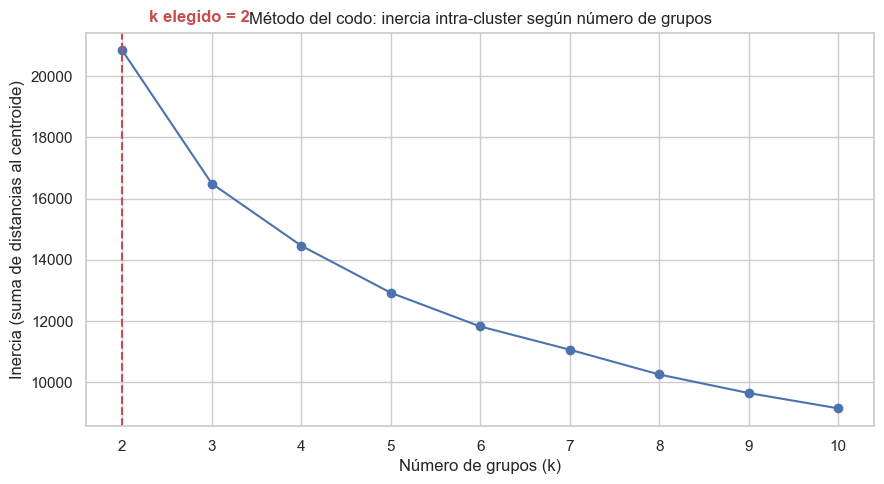

In [4]:
# --- Figura 1: curva de codo (inercia vs k), con el k elegido marcado ---
ks = [c['k'] for c in curvas]
inercias = [c['inercia'] for c in curvas]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ks, inercias, marker='o', color=sns.color_palette('deep')[0])
ax.axvline(k, color=sns.color_palette('deep')[3], linestyle='--', linewidth=1.5)
# Anotación del k elegido sobre su punto.
y_k = [c['inercia'] for c in curvas if c['k'] == k][0]
ax.annotate(f'k elegido = {k}', xy=(k, y_k),
            xytext=(k + 0.3, y_k + 0.08 * (max(inercias) - min(inercias))),
            color=sns.color_palette('deep')[3], fontweight='bold')
ax.set_title('Método del codo: inercia intra-cluster según número de grupos')
ax.set_xlabel('Número de grupos (k)')
ax.set_ylabel('Inercia (suma de distancias al centroide)')
ax.set_xticks(ks)
plt.tight_layout()
utils.save_fig(fig, 'fig_clustering_codo.png')
plt.show()

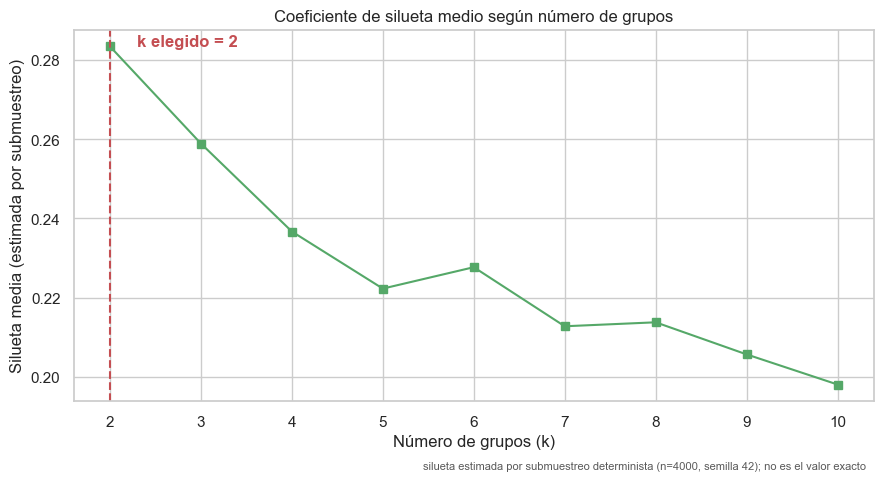

In [5]:
# --- Figura 2: curva de silueta (silueta vs k), con el k elegido marcado ---
siluetas = [c['silueta'] for c in curvas]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ks, siluetas, marker='s', color=sns.color_palette('deep')[2])
ax.axvline(k, color=sns.color_palette('deep')[3], linestyle='--', linewidth=1.5)
y_k = [c['silueta'] for c in curvas if c['k'] == k][0]
ax.annotate(f'k elegido = {k}', xy=(k, y_k),
            xytext=(k + 0.3, y_k),
            color=sns.color_palette('deep')[3], fontweight='bold')
ax.set_title('Coeficiente de silueta medio según número de grupos')
ax.set_xlabel('Número de grupos (k)')
ax.set_ylabel('Silueta media (estimada por submuestreo)')
ax.set_xticks(ks)
# Nota de encuadre: la silueta es una estimación por submuestreo determinista.
ax.text(0.99, -0.16, meta['silueta_nota'], transform=ax.transAxes,
        ha='right', va='top', fontsize=8, color='0.35')
plt.tight_layout()
utils.save_fig(fig, 'fig_clustering_silueta.png')
plt.show()

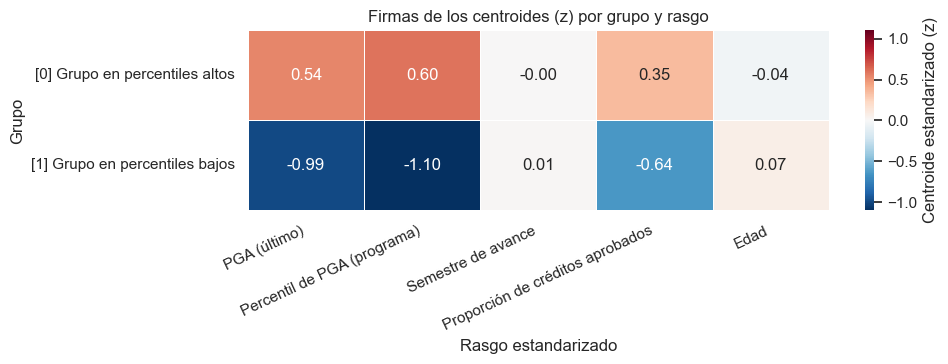

In [6]:
# --- Figura 3: mapa de calor de las firmas z de los centroides ---
# Matriz clusters x features con el valor z del centroide; rampa divergente
# centrada en 0 (z=0 es la media global). Anotación numérica por celda.
feat_vars = [f['var'] for f in meta['features']]
feat_labels = [f['label'] for f in meta['features']]
Z = np.array([
    [next(d['z'] for d in c['centroide_z'] if d['var'] == v) for v in feat_vars]
    for c in clusters
], dtype=float)
etiquetas_cluster = [f"[{c['id']}] {c['etiqueta']}" for c in clusters]

vmax = float(np.nanmax(np.abs(Z))) if Z.size else 1.0
fig, ax = plt.subplots(figsize=(1.6 * len(feat_labels) + 2, 0.9 * len(clusters) + 2))
sns.heatmap(Z, annot=True, fmt='.2f', cmap='RdBu_r', center=0.0,
            vmin=-vmax, vmax=vmax, linewidths=0.5, linecolor='white',
            xticklabels=feat_labels, yticklabels=etiquetas_cluster,
            cbar_kws={'label': 'Centroide estandarizado (z)'}, ax=ax)
ax.set_title('Firmas de los centroides (z) por grupo y rasgo')
ax.set_xlabel('Rasgo estandarizado')
ax.set_ylabel('Grupo')
plt.setp(ax.get_xticklabels(), rotation=25, ha='right')
plt.setp(ax.get_yticklabels(), rotation=0)
plt.tight_layout()
utils.save_fig(fig, 'fig_clustering_heatmap.png')
plt.show()

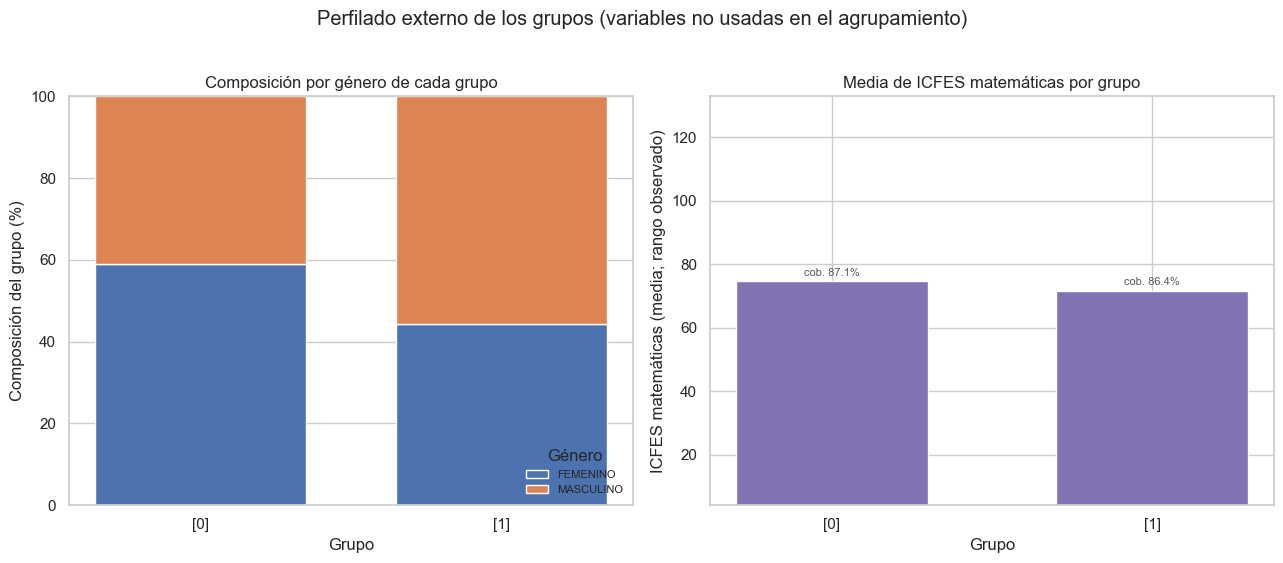

In [7]:
# --- Figura 4: perfil externo (composición por género + media ICFES matemáticas) ---
# Dos paneles de perfilado con variables NO usadas como feature:
#  (a) composición de género por cluster (barras apiladas a 100%);
#  (b) media de ICFES matemáticas por cluster con su cobertura, eje en el rango
#      observado (meta.escalas_perfil), NO 0-100.
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(13, 5.5))

# (a) Composición de género por cluster.
cats_genero = []
for c in clusters:
    pg = next(p for p in c['perfil_categorico'] if p['var'] == 'GENERO')
    for d in pg['distribucion']:
        cats_genero.append({'cluster': f"[{c['id']}]", 'categoria': d['categoria'],
                            'pct': d['pct']})
dfg = pd.DataFrame(cats_genero)
pivg = dfg.pivot_table(index='cluster', columns='categoria', values='pct',
                       aggfunc='sum').fillna(0.0)
base = np.zeros(len(pivg))
x = np.arange(len(pivg))
colores = sns.color_palette('deep', n_colors=pivg.shape[1])
for color, col in zip(colores, pivg.columns):
    vals = pivg[col].to_numpy()
    ax_a.bar(x, vals, bottom=base, label=str(col), color=color, width=0.7)
    base = base + vals
ax_a.set_xticks(x)
ax_a.set_xticklabels(pivg.index, rotation=0)
ax_a.set_ylim(0, 100)
ax_a.set_ylabel('Composición del grupo (%)')
ax_a.set_xlabel('Grupo')
ax_a.set_title('Composición por género de cada grupo')
ax_a.legend(title='Género', frameon=False, loc='lower right', fontsize=8)

# (b) Media de ICFES matemáticas por cluster, eje en rango observado.
var_icfes = 'ICFES_MATEMATICAS'
medias, coberturas, etq = [], [], []
for c in clusters:
    pm = next(p for p in c['perfil_numerico'] if p['var'] == var_icfes)
    medias.append(pm['media'])
    coberturas.append(pm['cobertura_pct'])
    etq.append(f"[{c['id']}]")
ax_b.bar(np.arange(len(clusters)), medias, color=sns.color_palette('deep')[4],
         width=0.6)
ax_b.set_xticks(np.arange(len(clusters)))
ax_b.set_xticklabels(etq, rotation=0)
# Eje Y en el rango observado (min/max de meta.escalas_perfil), NO 0-100.
esc = meta['escalas_perfil'].get(var_icfes, {})
if esc.get('min') is not None and esc.get('max') is not None:
    margen = 0.05 * (esc['max'] - esc['min'])
    ax_b.set_ylim(esc['min'] - margen, esc['max'] + margen)
ax_b.set_ylabel('ICFES matemáticas (media; rango observado)')
ax_b.set_xlabel('Grupo')
ax_b.set_title('Media de ICFES matemáticas por grupo')
# Nota de cobertura por grupo bajo cada barra.
for xi, (m, cov) in enumerate(zip(medias, coberturas)):
    if m is not None:
        ax_b.annotate(f'cob. {cov}%', xy=(xi, m), xytext=(0, 4),
                      textcoords='offset points', ha='center', fontsize=8,
                      color='0.35')
fig.suptitle('Perfilado externo de los grupos (variables no usadas en el agrupamiento)',
             y=1.02)
plt.tight_layout()
utils.save_fig(fig, 'fig_clustering_perfil_externo.png')
plt.show()

### Interpretación
El mapa de calor resume la **firma** de cada grupo: qué rasgos están por encima
($z>0$) o por debajo ($z<0$) de la media global. El perfil externo contrasta los
grupos con variables **no** usadas en el agrupamiento (género, ICFES), leídas
siempre con su cobertura y en el rango observado de cada escala.

## 3. Tablas (CSV + .tex booktabs)
Tres tablas, escritas como **CSV** en `reports/tables/` (fuente neutra, sin coma
decimal) y como **`.tex` booktabs** en `latex/tablas/` (lo que el informe `\input`).
La precisión por columna se deriva del **mismo** dict `cl.DECIMALES` (fuente única de
redondeo).

In [8]:
# --- Tabla 1: perfiles (una fila por cluster: etiqueta, n, %, centroide orig x5) ---
filas_perf = []
for c in clusters:
    cen = {d['var']: d['valor'] for d in c['centroide']}
    filas_perf.append({
        'etiqueta': c['etiqueta'],
        'n': c['n'],
        'pct': c['pct'],
        'PGA_ULTIMO': cen.get('PGA_ULTIMO'),
        'PERCENTIL_PGA_PROGRAMA': cen.get('PERCENTIL_PGA_PROGRAMA'),
        'SEMESTRE_AVANCE': cen.get('SEMESTRE_AVANCE'),
        'PCT_CREDITOS_APROBADOS': cen.get('PCT_CREDITOS_APROBADOS'),
        'EDAD': cen.get('EDAD'),
    })
df_perf = pd.DataFrame(filas_perf)
df_perf.to_csv(config.TABLES_DIR / 'clustering_perfiles.csv', index=False, encoding='utf-8')

cols_perf = [
    ('etiqueta', 'Grupo'), ('n', 'n'), ('pct', '%'),
    ('PGA_ULTIMO', 'PGA (0–5)'), ('PERCENTIL_PGA_PROGRAMA', 'Percentil PGA'),
    ('SEMESTRE_AVANCE', 'Avance (sem)'),
    ('PCT_CREDITOS_APROBADOS', 'Créditos aprob. (0–1)'), ('EDAD', 'Edad'),
]
tex_perf = df_to_latex_booktabs(df_perf, cols_perf, cl.DECIMALES, longtable=False,
                                caption=None, label=None)
(LATEX_TABLAS / 'clustering_perfiles.tex').write_text(tex_perf, encoding='utf-8')
print('clustering_perfiles: CSV + .tex OK (', len(df_perf), 'filas )')

clustering_perfiles: CSV + .tex OK ( 2 filas )


In [9]:
# --- Tabla 2: perfil ICFES/estrato por cluster (media, n_con_dato, cobertura) ---
# Una fila por (cluster, variable) de perfil numérico ICFES/estrato; el estrato es
# un indicador ordinal (media orientativa). Nota de cobertura al pie de la sección.
vars_icfes_estrato = ['ICFES_PUNTAJE_TOTAL', 'ICFES_MATEMATICAS',
                      'ICFES_LECTURA_CRITICA', 'ICFES_INGLES', 'ESTRATO_SOCIAL']
filas_ie = []
for c in clusters:
    pm = {p['var']: p for p in c['perfil_numerico']}
    for v in vars_icfes_estrato:
        p = pm.get(v, {})
        filas_ie.append({
            'grupo': c['etiqueta'],
            'variable': p.get('label', v),
            'media': p.get('media'),
            'n_con_dato': p.get('n_con_dato'),
            'cobertura_pct': p.get('cobertura_pct'),
        })
df_ie = pd.DataFrame(filas_ie)
df_ie.to_csv(config.TABLES_DIR / 'clustering_perfil_icfes_estrato.csv',
             index=False, encoding='utf-8')

cols_ie = [
    ('grupo', 'Grupo'), ('variable', 'Variable'), ('media', 'Media'),
    ('n_con_dato', 'n con dato'), ('cobertura_pct', 'Cobertura (%)'),
]
dec_ie = {'grupo': None, 'variable': None, 'media': cl.DECIMALES['media'],
          'n_con_dato': None, 'cobertura_pct': cl.DECIMALES['cobertura_pct']}
tex_ie = df_to_latex_booktabs(df_ie, cols_ie, dec_ie, longtable=False,
                              caption=None, label=None)
tex_ie = (
    "% Medias de cobertura parcial: leer junto a 'Cobertura (%)'. El estrato social es\n"
    "% un indicador ORDINAL orientativo (su media no es una magnitud de intervalo).\n"
    + tex_ie + "\n"
)
(LATEX_TABLAS / 'clustering_perfil_icfes_estrato.tex').write_text(tex_ie, encoding='utf-8')
print('clustering_perfil_icfes_estrato: CSV + .tex OK (', len(df_ie), 'filas )')

clustering_perfil_icfes_estrato: CSV + .tex OK ( 10 filas )


In [10]:
# --- Tabla 3: composición categórica por cluster (dimensión clave: FACULTAD) ---
# Una fila por (cluster, categoría) con n y %; las categorías con n<30 ya vienen
# suprimidas/agrupadas en 'Otras' por la fuente única (Ley 1581).
dim_cat = 'FACULTAD'
filas_cat = []
for c in clusters:
    pc = next(p for p in c['perfil_categorico'] if p['var'] == dim_cat)
    for d in pc['distribucion']:
        filas_cat.append({
            'grupo': c['etiqueta'],
            'categoria': d['categoria'],
            'n': d['n'],
            'pct': d['pct'],
        })
df_cat = pd.DataFrame(filas_cat)
df_cat.to_csv(config.TABLES_DIR / 'clustering_perfil_categorico.csv',
              index=False, encoding='utf-8')

cols_cat = [
    ('grupo', 'Grupo'), ('categoria', 'Facultad'), ('n', 'n'), ('pct', '%'),
]
dec_cat = {'grupo': None, 'categoria': None, 'n': None, 'pct': cl.DECIMALES['pct']}
tex_cat = df_to_latex_booktabs(df_cat, cols_cat, dec_cat, longtable=True,
    caption='Composición por facultad de cada grupo del clustering (participantes de pregrado; categorías con n<30 agregadas en «Otras» por privacidad).',
    label='tab:clustering-categorico')
(LATEX_TABLAS / 'clustering_perfil_categorico.tex').write_text(tex_cat, encoding='utf-8')
print('clustering_perfil_categorico: CSV + .tex OK (', len(df_cat), 'filas )')

clustering_perfil_categorico: CSV + .tex OK ( 17 filas )


## 4. Copia de figuras a `latex/figuras/`
El informe usa `\graphicspath{{figuras/}}`, por lo que las PNG deben estar en
`latex/figuras/`. Se copian desde `reports/figures/` con rutas absolutas.

In [11]:
for png in ['fig_clustering_codo.png', 'fig_clustering_silueta.png',
            'fig_clustering_heatmap.png', 'fig_clustering_perfil_externo.png']:
    shutil.copy2(config.FIGURES_DIR / png, LATEX_FIG / png)
    print('copiada ->', (LATEX_FIG / png).name)

copiada -> fig_clustering_codo.png
copiada -> fig_clustering_silueta.png
copiada -> fig_clustering_heatmap.png
copiada -> fig_clustering_perfil_externo.png


## 5. Narrativa (cifras interpoladas, M2)
La prosa que acompaña al informe la construye la **fuente única**
(`cl.construir_narrativa_clustering`): cero cifras tecleadas a mano, cada magnitud
interpolada desde `out`. Es la misma prosa que `data.json`. Para el `.tex` se escapan
los caracteres especiales de LaTeX (sobre todo el `%`, que inicia comentario); las
cifras no cambian.

In [12]:
# La narrativa ya la construye la fuente única (misma prosa que data.json).
narrativa = out['narrativa']
assert narrativa == cl.construir_narrativa_clustering(out), \
    'La narrativa del dict no coincide con construir_narrativa_clustering (fuente única).'

def _escapar_tex(texto):
    '''Escapa % & # $ _ para LaTeX sin alterar las cifras interpoladas.'''
    for kk, vv in (('&', r'\&'), ('%', r'\%'), ('#', r'\#'),
                   ('$', r'\$'), ('_', r'\_')):
        texto = texto.replace(kk, vv)
    return texto

tex_narrativa = (
    "% Narrativa generada automaticamente desde clustering_participantes (M2): NO editar a mano.\n"
    "% Cada cifra esta interpolada desde compute_clustering; regenerar actualiza el texto.\n"
    + _escapar_tex(narrativa) + "\n"
)
(LATEX_TABLAS / 'clustering_narrativa.tex').write_text(tex_narrativa, encoding='utf-8')
print('clustering_narrativa.tex escrita. Longitud:', len(narrativa), 'caracteres.')
print('\n' + narrativa)

clustering_narrativa.tex escrita. Longitud: 991 caracteres.

Sobre 5.815 participantes de pregrado con datos completos (de 5.821 participantes de pregrado y 8.036 participantes en todos los niveles), el agrupamiento K-means identifica 2 perfiles internos a partir de cinco rasgos académicos y demográficos estandarizados. En concreto, el grupo «Grupo en percentiles altos» reúne 3.761 estudiantes (64,7%), caracterizado sobre todo por percentil de pga (programa); el grupo «Grupo en percentiles bajos» reúne 2.054 estudiantes (35,3%), caracterizado sobre todo por percentil de pga (programa). Entre las variables de perfilado externas, «ICFES puntaje total» es la que más diferencia a los grupos; sus medias se calculan solo sobre quienes tienen dato (cobertura parcial en los puntajes ICFES y en el estrato). Estos agrupamientos son descriptivos, no categorías administrativas ni relaciones causales; la media de estrato es un indicador ordinal orientativo y todas las medias de cobertura parcial de

## 6. Verificación de consistencia (M1)
Esta celda **falla el build** (`python build_notebooks.py 08`) si las cifras que el
informe REALMENTE renderiza divergen de la fuente única. Compara, a la precisión
publicada (`cl.DECIMALES`), tres cantidades entre **tres orígenes** ---`out`
(cálculo), `data.json` clave `clustering` (web) y el **CSV renderizado** del
informe---:

1. el `k` elegido (meta);
2. `n`, `pct` y un componente del centroide (`PGA_ULTIMO`) del **cluster 0** bajo el
   orden canónico;
3. la **silueta** del `k` elegido en las curvas.

No se limita a comparar `data.json` contra `compute_clustering`: incluye el artefacto
que el informe imprime (CSV/.tex), que es lo que el lector ve. Requiere que
`python -m src.export_dashboard` se haya corrido antes.

In [13]:
def _r(valor, campo):
    '''Redondea a la precisión publicada; None si no hay dato.'''
    if valor is None:
        return None
    return round(float(valor), cl.DECIMALES[campo])

# (1) Desde out (cálculo).
k_out = out['meta']['k_elegido']
c0_out = out['clusters'][0]
pga0_out = next(d['valor'] for d in c0_out['centroide'] if d['var'] == 'PGA_ULTIMO')
sil_out = next(c['silueta'] for c in out['curvas'] if c['k'] == k_out)

# (2) Desde data.json (lo que consume la web).
data_json = json.loads(DATA_JSON.read_text(encoding='utf-8'))
clj = data_json['clustering']
k_json = clj['meta']['k_elegido']
c0_json = clj['clusters'][0]
pga0_json = next(d['valor'] for d in c0_json['centroide'] if d['var'] == 'PGA_ULTIMO')
sil_json = next(c['silueta'] for c in clj['curvas'] if c['k'] == k_json)

# (3) Desde el CSV renderizado (fuente directa del .tex del informe).
with open(config.TABLES_DIR / 'clustering_perfiles.csv', encoding='utf-8') as fh:
    filas_csv = list(csv.DictReader(fh))
# El cluster 0 es la primera fila (orden canónico preservado al construir la tabla).
c0_csv = filas_csv[0]
n0_csv = int(c0_csv['n'])
pct0_csv = float(c0_csv['pct'])
pga0_csv = float(c0_csv['PGA_ULTIMO'])

# --- (i) k elegido (out == json) ---
assert k_out == k_json, f'Inconsistencia k elegido: out={k_out} json={k_json}'

# --- (ii) n, pct y PGA_ULTIMO del cluster 0 (out == json == csv) ---
assert c0_out['n'] == c0_json['n'] == n0_csv, \
    f"Inconsistencia n cluster 0: out={c0_out['n']} json={c0_json['n']} csv={n0_csv}"
p_out = _r(c0_out['pct'], 'pct'); p_json = _r(c0_json['pct'], 'pct'); p_csv = _r(pct0_csv, 'pct')
assert p_out == p_json == p_csv, \
    f'Inconsistencia pct cluster 0: out={p_out} json={p_json} csv={p_csv}'
g_out = _r(pga0_out, 'PGA_ULTIMO'); g_json = _r(pga0_json, 'PGA_ULTIMO'); g_csv = _r(pga0_csv, 'PGA_ULTIMO')
assert g_out == g_json == g_csv, \
    f'Inconsistencia PGA_ULTIMO cluster 0: out={g_out} json={g_json} csv={g_csv}'

# --- (iii) silueta del k elegido en las curvas (out == json) ---
s_out = _r(sil_out, 'silueta'); s_json = _r(sil_json, 'silueta')
assert s_out == s_json, f'Inconsistencia silueta k={k_out}: out={s_out} json={s_json}'

print('[M1] Consistencia verificada (out == data.json == CSV/.tex):')
print(f'  k elegido                       = {k_out}')
print(f'  cluster 0: n={c0_out["n"]:,} | pct={p_out}% | PGA_ULTIMO={g_out}')
print(f'  silueta (k={k_out})              = {s_out}')
print('[M1] OK — ninguna divergencia.')

[M1] Consistencia verificada (out == data.json == CSV/.tex):
  k elegido                       = 2
  cluster 0: n=3,761 | pct=64.7% | PGA_ULTIMO=4.29
  silueta (k=2)              = 0.2834
[M1] OK — ninguna divergencia.


### Cierre
Con esta celda en verde, los artefactos del clustering quedan garantizados como
coherentes con el dashboard: misma fuente de cálculo, mismo redondeo y las cifras
críticas verificadas sobre el CSV/.tex que el informe efectivamente imprime. Si en el
futuro alguien cambiara el cálculo sin regenerar los artefactos, este notebook
fallaría y detendría el build, protegiendo la consistencia web↔informe (RNF-1).